In [110]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Exercício 1

Considere $X\sim\operatorname{Gamma}(3,2)$. Estime por Monte Carlo

$$
\mu=E[\sqrt{X}].
$$

Calcule a variância do estimador e construa um intervalo de confiança de 95%. Compare com o valor teórico.

**Valor teórico:**

$$
\mu=\frac{\Gamma(7/2)}{\Gamma(3)\sqrt{2}}\approx 1{,}174982.
$$

# Exercício 2

Considere $X\sim\operatorname{Beta}(2,5)$. Estime por Monte Carlo

$$
p=P(X>0{,}4).
$$

Calcule a variância do estimador e construa um intervalo de confiança de 95%.

**Valor teórico:** $p=0{,}23328$.

# Exercício 3

Considere a integral

$$
I=\frac{1}{\sqrt{8\pi}}\int_{-\infty}^{\infty}(x^2+2x+1)e^{-(x-1)^2/8}\,dx.
$$

Utilizando $X\sim N(1,4)$, reescreva a integral como uma esperança e estime $I$ por Monte Carlo. Calcule a variância do estimador e construa um intervalo de confiança de 95%.

**Valor teórico:** $I=8$.

# Exercício 4

Considere $X\sim\operatorname{Gamma}(2,1)$ e $Y\sim\operatorname{Exp}(1)$, independentes. Estime por Monte Carlo

$$
p=P(X>Y).
$$

Calcule a variância do estimador e construa um intervalo de confiança de 95%.

**Valor teórico:** $p=0{,}75$.


# Exercício 5

Considere a integral

$$
I=\int_0^1 x^2(1-x)^3e^x\,dx.
$$

Utilizando $X\sim\operatorname{Beta}(3,4)$, reescreva a integral como uma esperança e estime $I$ por Monte Carlo. Calcule a variância do estimador e construa um intervalo de confiança de 95%.

**Valor teórico:**

$$
I=B(3,4)E[e^X]=\frac{E[e^X]}{60}\approx 0{,}02598262,
\qquad X\sim\operatorname{Beta}(3,4).
$$

# Exercício 6

Considere $X,Y\overset{\mathrm{iid}}{\sim}N(0,1)$. Estime por Monte Carlo

$$
p=P(X^2+Y^2>5).
$$

Calcule a variância do estimador e construa um intervalo de confiança de 95%. Compare com a distribuição qui-quadrado.

**Valor teórico:**

$$
p=e^{-5/2}\approx 0{,}082085.
$$

# Exercício 7

Considere $X_1,\ldots,X_5$ independentes, com $X_i\sim\operatorname{Exp}(2)$. Defina

$$
M=\max(X_1,\ldots,X_5).
$$

Estime $E[M]$ por Monte Carlo. Calcule a variância do estimador e construa um intervalo de confiança de 95%.

**Valor teórico:**

$$
E[M]=\frac{1}{2}\sum_{k=1}^{5}\frac{1}{k}\approx 1{,}141667.
$$

# Exercício 8

Considere $X=e^Z$, com $Z\sim N(0,1)$. Estime por Monte Carlo

$$
\mu=E[X]
\qquad\text{e}\qquad
p=P(X>10).
$$

Calcule as variâncias dos respectivos estimadores e construa intervalos de confiança de 95%.

**Valores teóricos:**

$$
\mu=e^{1/2}\approx 1{,}648721,
\qquad
p=1-\Phi(\ln 10)\approx 0{,}0106511.
$$

# Exercício 9

Considere $X_1,\ldots,X_4$ independentes, com $X_i\sim\operatorname{Exp}(2)$. Defina

$$
M=\min(X_1,\ldots,X_4).
$$

Estime $E[M]$ por Monte Carlo. Calcule a variância do estimador e construa um intervalo de confiança de 95%.

**Valor teórico:** $M\sim\operatorname{Exp}(8)$ e $E[M]=0{,}125$.


In [111]:
np.random.seed(4)

In [112]:
#Exercicio 1
#Construindo Gama
amostra_gama = []
N = 10**4
for i in range(N):
  gama = []
  for i in range(3):
    u = np.random.uniform()
    exp = -(1/2)*np.log(u)
    gama.append(exp)
  amostra_gama.append(np.sum(gama))

#Estimação Mi
amostra_final = []
for valor in amostra_gama:
  amostra_final.append(np.sqrt(valor))

mi = np.mean(amostra_final)

In [113]:
var = np.var(amostra_gama)
dp = np.sqrt(var)

IC_min, IC_max = mi-2*dp/np.sqrt(N),mi+2*dp/np.sqrt(N)

print(f"Estimativa Pontual para mi: {mi:.4f}")
print(f"Intervalo de Confiaça 95% para mi: {float(IC_min),float(IC_max)}")

Estimativa Pontual para mi: 1.1789
Intervalo de Confiaça 95% para mi: (1.161434528815533, 1.196369728123337)


In [114]:
#Exercicio 2
def f(x,alpha,beta):
  B = math.gamma(alpha+beta)/(math.gamma(alpha)*math.gamma(beta))
  f = (x**(alpha-1) * (1-x)**(beta-1))/B
  return f

alpha = 2
beta = 5
y_star = (alpha - 1)/(alpha+beta-2)

c = f(y_star,alpha,beta)

In [115]:
amostra_beta = []
N = 10**4
for i in range(N):
  y = np.random.uniform()
  u = np.random.uniform()

  while u >= f(y,alpha,beta)/c:
    y = np.random.uniform()
    u = np.random.uniform()

  x = y
  if x>0.4:
    amostra_beta.append(1)
  else:
    amostra_beta.append(0)

p = np.mean(amostra_beta)

In [116]:
var = np.var(amostra_beta)
dp = np.sqrt(var)

IC_min, IC_max = p-2*dp/np.sqrt(N),p+2*dp/np.sqrt(N)

print(f"Estimativa Pontual para mi: {p:.4f}")
print(f"Intervalo de Confiaça 95% para mi: {float(IC_min),float(IC_max)}")

Estimativa Pontual para mi: 0.2291
Intervalo de Confiaça 95% para mi: (0.22069492558034137, 0.23750507441965862)


In [117]:
#Exercicio 3
#Função Normal por Box-Muller
def Normal(mi,sigma2):
    u1 = np.random.uniform()
    u2 = np.random.uniform()

    u_2pi = 2*np.pi*u1
    t = -np.log(u2)
    x = np.sqrt(2*t)*np.cos(u_2pi)

    return np.sqrt(sigma2)*x + mi

N = 10**4
amostra_normal = []
for i in range(N):
  valor = Normal(1,4)
  amostra_normal.append((valor+1)**2)

I = np.mean(amostra_normal)

In [118]:
variance = np.var(amostra_normal)
standart_deviation = np.sqrt(variance)

IC_min, IC_max = I-2*standart_deviation/np.sqrt(N),I+2*standart_deviation/np.sqrt(N)

In [119]:
print(f"Estimativa Pontual: {I:.4f}")
print(f"Intervalo de Confiaça 95%: {float(IC_min),float(IC_max)}")

Estimativa Pontual: 7.9503
Intervalo de Confiaça 95%: (7.756018508589754, 8.144610428663626)


In [120]:
#Exercicio 4
def Gama_inteiro(k,lamb):
    gama = []
    for i in range(k):
        u = np.random.uniform()
        exp = -(1/lamb)*np.log(1-u)
        gama.append(exp)

    return np.sum(gama)


def exponencial(lamb):
    u = np.random.uniform()
    return -(1/lamb)*np.log(1-u)

p = []
N = 10**4

for i in range(N):

  if Gama_inteiro(2,1) > exponencial(1):
    p.append(1)
  else:
    p.append(0)

p_chapeu = np.mean(p)

In [121]:
var = np.var(p)
dp = np.sqrt(var)

IC_min, IC_max = p_chapeu-2*dp/np.sqrt(N),p_chapeu+2*dp/np.sqrt(N)

print(f"Estimativa Pontual: {p_chapeu:.4f}")
print(f"Intervalo de Confiaça 95%: {float(IC_min),float(IC_max)}")

Estimativa Pontual: 0.7527
Intervalo de Confiaça 95%: (0.7440711481644428, 0.7613288518355573)


In [122]:
#Exercicio 5
#Beta
def Beta(alpha,beta):
    def f(x,alpha,beta):
        B = math.gamma(alpha+beta)/(math.gamma(alpha)*math.gamma(beta))
        f = (x**(alpha-1) * (1-x)**(beta-1))/B
        return f

    y_star = (alpha - 1)/(alpha+beta-2)

    c = f(y_star,alpha,beta)

    y = np.random.uniform()
    u = np.random.uniform()

    while u >= f(y,alpha,beta)/c:
        y = np.random.uniform()
        u = np.random.uniform()

    x = y
    return x


N = 10**4
amostra_beta = []
for i in range(N):
  betinha = Beta(3,4)
  amostra_beta.append(np.exp(betinha)/60)
I_Beta = np.mean(amostra_beta)

In [123]:
var = np.var(amostra_beta)
dp = np.sqrt(var)

IC_min, IC_max = I_Beta-2*dp/np.sqrt(N),I_Beta+2*dp/np.sqrt(N)

print(f"Estimativa Pontual: {I_Beta:.4f}")
print(f"Intervalo de Confiaça 95%: {float(IC_min),float(IC_max)}")

Estimativa Pontual: 0.0261
Intervalo de Confiaça 95%: (0.025968106987926655, 0.02615287424596923)


In [124]:
#Exercicio 6
def Normal(mi,sigma2):
    u1 = np.random.uniform()
    u2 = np.random.uniform()

    u_2pi = 2*np.pi*u1
    t = -np.log(u2)
    x = np.sqrt(2*t)*np.cos(u_2pi)
    y = np.sqrt(2*t)*np.sin(u_2pi)

    return np.sqrt(sigma2)*x + mi, np.sqrt(sigma2)*y + mi

N = 10**4
amostra_phat = []
amostra_qui = []
for i in range(N):
  x,y = Normal(0,1)
  z = x**2 + y**2
  amostra_qui.append(z)
  amostra_phat.append(1 if z>5 else 0 )
p_hat = np.mean(amostra_phat)

In [125]:
var = np.var(amostra_phat)
dp = np.sqrt(var)

IC_min, IC_max = p_hat-2*dp/np.sqrt(N),p_hat+2*dp/np.sqrt(N)

print(f"Estimativa Pontual: {p_hat:.4f}")
print(f"Intervalo de Confiaça 95%: {float(IC_min),float(IC_max)}")

Estimativa Pontual: 0.0796
Intervalo de Confiaça 95%: (0.07418654121656035, 0.08501345878343966)


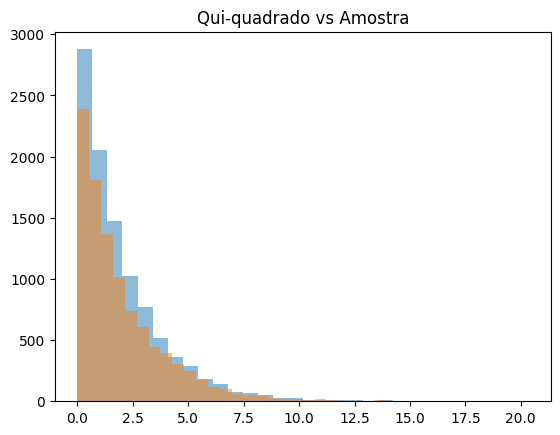

In [126]:
plt.hist(amostra_qui, bins=30, alpha = 0.5)
plt.hist(np.random.chisquare(2,10**4), bins = 30, alpha = 0.5)
plt.title("Qui-quadrado vs Amostra")
plt.show()

In [127]:
#Exercicio 7
#Exponencial
def exponencial(lamb):
    u = np.random.uniform()
    return -(1/lamb)*np.log(1-u)


amostra_maximos = []
N = 10**4

for j in range(N):
  max = 0
  for i in range(5):
    x = exponencial(2)
    if x>max:
      max= x
  amostra_maximos.append(max)

em = np.mean(amostra_maximos)

In [128]:
var = np.var(amostra_maximos)
dp = np.sqrt(var)

IC_min, IC_max = em-2*dp/np.sqrt(N),em+2*dp/np.sqrt(N)

print(f"Estimativa Pontual: {em:.4f}")
print(f"Intervalo de Confiaça 95%: {float(IC_min),float(IC_max)}")

Estimativa Pontual: 1.1399
Intervalo de Confiaça 95%: (1.1276996418378875, 1.1521218759577452)


In [129]:
def Normal(mi,sigma2):
    u1 = np.random.uniform()
    u2 = np.random.uniform()

    u_2pi = 2*np.pi*u1
    t = -np.log(u2)
    x = np.sqrt(2*t)*np.cos(u_2pi)

    return np.sqrt(sigma2)*x + mi


N = 10**4
amostra_mi = []
amostra_pz = []

for i in range(N):
  value = Normal(0,1)
  x = np.exp(value)
  amostra_mi.append(x)
  amostra_pz.append(1 if x>10 else 0)

p_estimado = np.mean(amostra_pz)
mi_estimado = np.mean(amostra_mi)

In [130]:
var = np.var(amostra_mi)
dp = np.sqrt(var)

IC_min, IC_max = mi_estimado-2*dp/np.sqrt(N),mi_estimado+2*dp/np.sqrt(N)

print(f"Estimativa Pontual para mi: {mi_estimado:.4f}")
print(f"Intervalo de Confiaça 95% para mi: {float(IC_min),float(IC_max)}")

var = np.var(amostra_pz)
dp = np.sqrt(var)

IC_min, IC_max = p_estimado-2*dp/np.sqrt(N),p_estimado+2*dp/np.sqrt(N)

print(f"Estimativa Pontual para p: {p_estimado:.4f}")
print(f"Intervalo de Confiaça 95% para p: {float(IC_min),float(IC_max)}")

Estimativa Pontual para mi: 1.6281
Intervalo de Confiaça 95% para mi: (1.5796743590770586, 1.6765828654216621)
Estimativa Pontual para p: 0.0099
Intervalo de Confiaça 95% para p: (0.007919900002525126, 0.011880099997474875)


In [131]:
#Exercicio 9
#Exponencial
def exponencial(lamb):
    u = np.random.uniform()
    return -(1/lamb)*np.log(1-u)


amostra_minimos = []
N = 10**4

for j in range(N):
  min = 10000
  for i in range(4):
    x = exponencial(2)
    if x < min:
      min = x
  amostra_minimos.append(min)

Em = np.mean(amostra_minimos)

In [132]:
var = np.var(amostra_minimos)
dp = np.sqrt(var)

IC_min, IC_max = Em-2*dp/np.sqrt(N),Em+2*dp/np.sqrt(N)

print(f"Estimativa Pontual: {Em:.4f}")
print(f"Intervalo de Confiaça 95%: {float(IC_min),float(IC_max)}")

Estimativa Pontual: 0.1245
Intervalo de Confiaça 95%: (0.12198498893982333, 0.12697453856249027)
